# Baseline Machine Learning Models

## Why Baselines Matter

Before investing time in complex ensemble models or deep learning, we establish reference models that answer a simple question:

> **"Is the more complex model actually better?"**

We'll evaluate every model using the same metrics.

---

# 7.1 Import Models

In [19]:
# Standard Libraries

import os
import gc
import random
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")


# Data Manipulation

import numpy as np
import pandas as pd


# Visualization

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8")
sns.set_palette("Set2")

# Machine Learning Models

import tensorflow as tf
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


# Evaluation


from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

from sklearn.metrics import (
    RocCurveDisplay,
    PrecisionRecallDisplay
)


In [20]:
# Project Configuration

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

FIGSIZE = (12,6)

print("TensorFlow Version :", tf.__version__)
print("NumPy Version      :", np.__version__)
print("Pandas Version     :", pd.__version__)

TensorFlow Version : 2.21.0
NumPy Version      : 2.5.1
Pandas Version     : 3.0.5


In [3]:
DATA_DIR = Path("data/Training_Datasets")

# -----------------------------
# Features
# -----------------------------
X_train_scaled = pd.read_csv(DATA_DIR / "X_train_scaled.csv")
X_valid_scaled = pd.read_csv(DATA_DIR / "X_valid_scaled.csv")
X_test_scaled  = pd.read_csv(DATA_DIR / "X_test_scaled.csv")

X_train_tree = pd.read_csv(DATA_DIR / "X_train_tree.csv")
X_valid_tree = pd.read_csv(DATA_DIR / "X_valid_tree.csv")
X_test_tree  = pd.read_csv(DATA_DIR / "X_test_tree.csv")

# -----------------------------
# Targets
# -----------------------------
y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze("columns")
y_valid = pd.read_csv(DATA_DIR / "y_valid.csv").squeeze("columns")
y_test  = pd.read_csv(DATA_DIR / "y_test.csv").squeeze("columns")

print("Datasets loaded successfully.")

Datasets loaded successfully.


---

# 6.8 Compute Class Weights

Instead of immediately applying SMOTE, we'll first use class weights.

In [11]:
from sklearn.utils.class_weight import compute_class_weight

In [12]:
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

In [13]:
class_weights = dict(
    zip(classes, weights)
)

print(class_weights)

{np.int64(0): np.float64(0.5182253535252231), np.int64(1): np.float64(14.217155041959003)}


Using class weights is a strong baseline for highly imbalanced fraud detection because it increases the cost of misclassifying minority-class examples without generating synthetic transactions. Many recent IEEE-CIS studies evaluate class weighting before introducing oversampling methods such as SMOTE.

# 7.2 Universal Evaluation Function

Instead of writing evaluation code repeatedly, let's build one reusable function.

In [25]:

# Universal Model Evaluation


def evaluate_model(model,
                   X_train_tree,
                   y_train,
                   X_test_tree,
                   y_test,
                   model_name="Model"):

    print("="*70)
    print(model_name)
    print("="*70)

    # Predictions
    y_pred = model.predict(X_test_tree)

    # Probabilities
    y_prob = model.predict_proba(X_test_tree)[:,1]

    # Metrics
    accuracy = accuracy_score(y_test, y_pred)

    balanced_acc = balanced_accuracy_score(
        y_test,
        y_pred
    )

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred
    )

    f1 = f1_score(
        y_test,
        y_pred
    )

    roc_auc = roc_auc_score(
        y_test,
        y_prob
    )

    pr_auc = average_precision_score(
        y_test,
        y_prob
    )

    results = pd.DataFrame({
        "Metric":[
            "Accuracy",
            "Balanced Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC-AUC",
            "PR-AUC"
        ],
        "Score":[
            accuracy,
            balanced_acc,
            precision,
            recall,
            f1,
            roc_auc,
            pr_auc
        ]
    })

    display(results)

    print("\nClassification Report\n")
    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5,4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title(f"{model_name} Confusion Matrix")

    plt.xlabel("Predicted")

    plt.ylabel("Actual")

    plt.show()

    RocCurveDisplay.from_predictions(
        y_test,
        y_prob
    )

    plt.show()

    PrecisionRecallDisplay.from_predictions(
        y_test,
        y_prob
    )

    plt.show()

    return results

---

# 7.3 Dummy Classifier

This predicts the majority class and provides the minimum acceptable performance.

In [26]:
dummy = DummyClassifier(
    strategy="most_frequent"
)

dummy.fit(
    X_train_tree,
    y_train
)

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'most_frequent'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](2,)","[0.96,0.04]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](436,)","['TransactionDT','TransactionAmt','ProductCD',...,'card1_amt_max', 'Amount_to_CardMean','addr1_frequency']"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,436
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


Dummy Classifier


,Metric,Score
0,Accuracy,0.965659
1,Balanced Accuracy,0.500000
2,Precision,0.000000
3,Recall,0.000000
4,F1,0.000000
5,ROC-AUC,0.500000
6,PR-AUC,0.034341



Classification Report

              precision    recall  f1-score   support

           0       0.97      1.00      0.98     85539
           1       0.00      0.00      0.00      3042

    accuracy                           0.97     88581
   macro avg       0.48      0.50      0.49     88581
weighted avg       0.93      0.97      0.95     88581



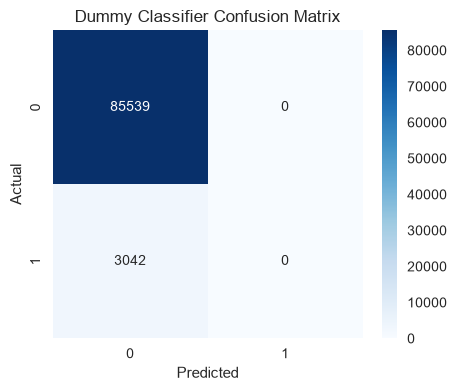

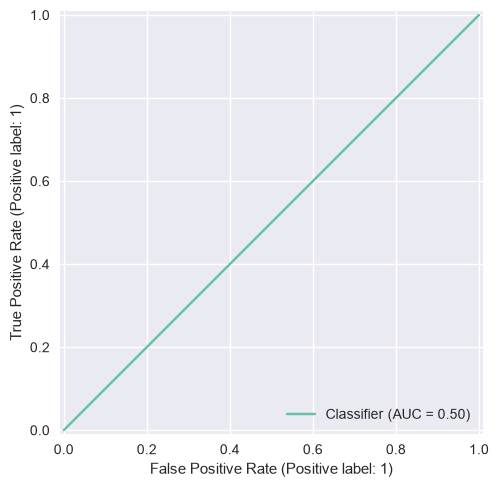

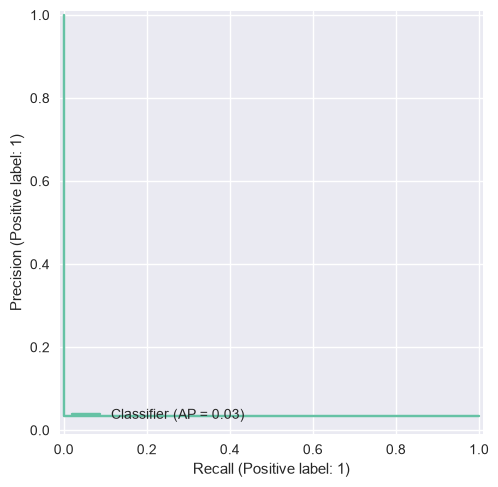

In [27]:
dummy_results = evaluate_model(
    dummy,
    X_train_tree,
    y_train,
    X_valid_tree,
    y_valid,
    "Dummy Classifier"
)

The Dummy Classifier will likely achieve a high **accuracy** because the dataset is dominated by legitimate transactions, but its recall and precision for fraud will be effectively zero. This illustrates why **accuracy is a poor metric** for fraud detection and why metrics such as PR-AUC, recall, and F1 are preferred for highly imbalanced problems.

---

# 7.4 Logistic Regression

We'll use class weights rather than oversampling for our initial baseline.

In [37]:
logistic = LogisticRegression(
    max_iter=1000,
    class_weight=class_weights,
    random_state=RANDOM_STATE,
    solver="lbfgs",
    n_jobs=-1
)

Train the model.

In [38]:
logistic.fit(
    X_train_scaled,
    y_train
)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*","{np.int64(0): np.float64(0.5182253535252231), np.int64(1): np.float64(14.217155041959003)}"
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"n_jobs n_jobs: int, default=NoneDoes not have any effect... deprecated:: 1.8 `n_jobs` is deprecated in version 1.8 and will be removed in 1.10.",-1
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (a

In [39]:
y_train_pred = logistic.predict(X_train_scaled)
y_train_prob = logistic.predict_proba(X_train_scaled)[:, 1]

In [49]:
y_valid_pred = logistic.predict(X_valid_scaled)
y_valid_prob = logistic.predict_proba(X_valid_scaled)[:, 1]

Evaluate.

Logistic Regression


,Metric,Score
0,Accuracy,0.673993
1,Balanced Accuracy,0.744489
2,Precision,0.080938
3,Recall,0.820184
4,F1,0.147337
5,ROC-AUC,0.845911
6,PR-AUC,0.388761



Classification Report

              precision    recall  f1-score   support

           0       0.99      0.67      0.80     85539
           1       0.08      0.82      0.15      3042

    accuracy                           0.67     88581
   macro avg       0.54      0.74      0.47     88581
weighted avg       0.96      0.67      0.78     88581



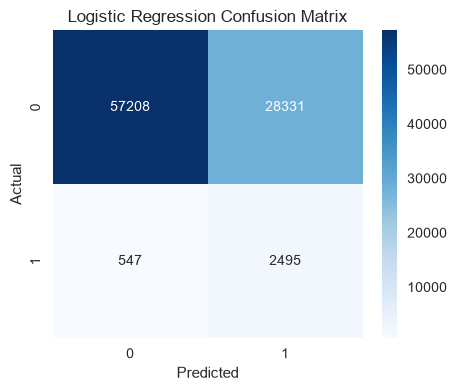

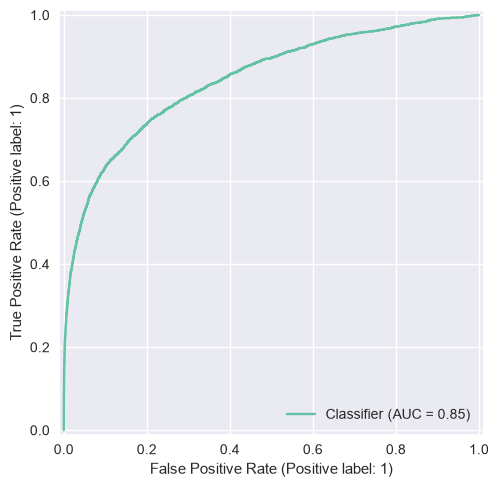

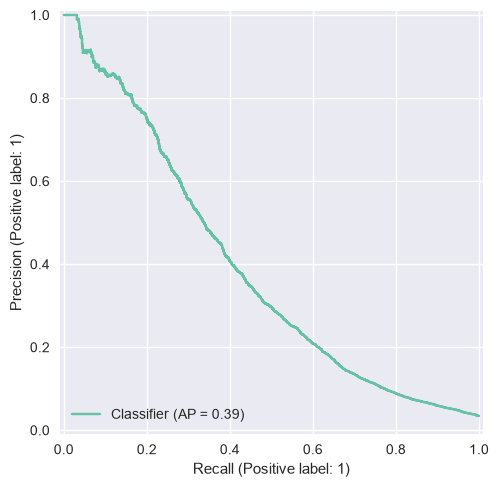

In [50]:
logistic_results = evaluate_model(
    logistic,
    X_train_scaled,
    y_train,
    X_valid_scaled,
    y_valid,
    "Logistic Regression"
)

---

# 7.5 Decision Tree

Our first non-linear model.

In [51]:
tree = DecisionTreeClassifier(
    max_depth=10,
    min_samples_leaf=20,
    class_weight=class_weights,
    random_state=RANDOM_STATE
)

In [52]:
tree.fit(
    X_train_tree,
    y_train
)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.","{np.int64(0): np.float64(0.5182253535252231), np.int64(1): np.float64(14.217155041959003)}"
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_featu

Decision Tree


,Metric,Score
0,Accuracy,0.847123
1,Balanced Accuracy,0.770090
2,Precision,0.142419
3,Recall,0.687377
4,F1,0.235951
5,ROC-AUC,0.825760
6,PR-AUC,0.356432



Classification Report

              precision    recall  f1-score   support

           0       0.99      0.85      0.92     85539
           1       0.14      0.69      0.24      3042

    accuracy                           0.85     88581
   macro avg       0.56      0.77      0.58     88581
weighted avg       0.96      0.85      0.89     88581



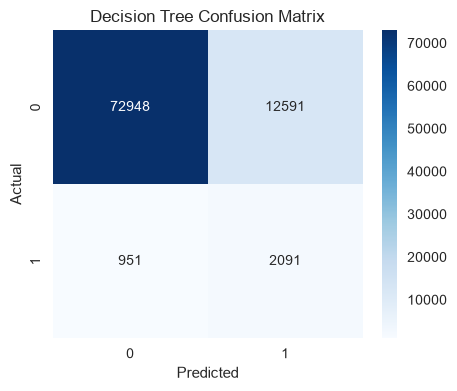

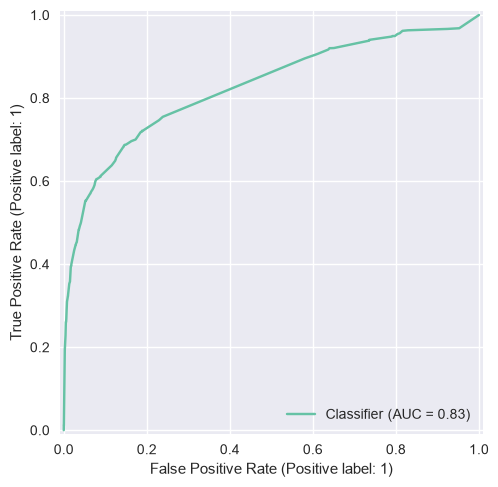

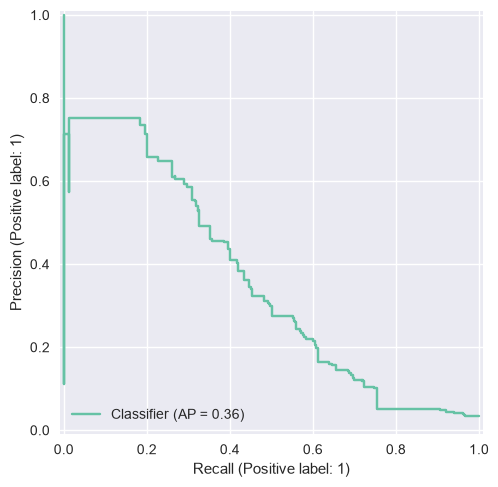

In [53]:
tree_results = evaluate_model(
    tree,
    X_train_tree,
    y_train,
    X_valid_tree,
    y_valid,
    "Decision Tree"
)

# 7.6 Compare Baseline Models

In [55]:
comparison = pd.concat([
    dummy_results.assign(Model="Dummy"),
    logistic_results.assign(Model="Logistic Regression"),
    tree_results.assign(Model="Decision Tree")
])

comparison = comparison.pivot(
    index="Metric",
    columns="Model",
    values="Score"
)

display(comparison)

Model,Decision Tree,Dummy,Logistic Regression
Metric,,,
Accuracy,0.847123,0.965659,0.673993
Balanced Accuracy,0.770090,0.500000,0.744489
F1,0.235951,0.000000,0.147337
PR-AUC,0.356432,0.034341,0.388761
Precision,0.142419,0.000000,0.080938
ROC-AUC,0.825760,0.500000,0.845911
Recall,0.687377,0.000000,0.820184


---

# 7.7 Which Model Wins?

At this point, don't choose the model based on **Accuracy**.

Instead, compare:

* ROC-AUC
* PR-AUC
* Recall
* Precision
* F1-score
* Balanced Accuracy

For fraud detection, **PR-AUC is often the most informative summary metric** because it focuses on the minority (fraud) class, while ROC-AUC can appear overly optimistic when the negative class dominates. Recent studies on IEEE-CIS and other highly imbalanced fraud datasets consistently emphasize PR-AUC, precision, and recall for model comparison.

**Note:** Current evaluation uses the default probability threshold of 0.5, which is rarely optimal in fraud detection. In production, organizations typically optimize the decision threshold on the validation set to balance fraud detection (recall) against false alarms (precision) according to business requirements, rather than relying on the default threshold. We'll implement threshold optimization before evaluating the more advanced models so that comparisons are both fair and operationally meaningful.

# Random Forest

Random Forest is usually the first strong baseline for structured/tabular datasets.

Advantages:

* Robust to outliers
* Handles nonlinear relationships
* No feature scaling required
* Resistant to overfitting compared to a single decision tree
* Provides feature importance

# 8.1 Import

In [56]:
from sklearn.ensemble import RandomForestClassifier

---

# 8.2 Initial Model

Instead of using defaults, let's use a reasonable starting configuration.

In [57]:
rf = RandomForestClassifier(

    n_estimators=300,

    max_depth=20,

    min_samples_leaf=5,

    max_features="sqrt",

    class_weight=class_weights,

    n_jobs=-1,

    random_state=RANDOM_STATE
)

---

# 8.3 Train

In [59]:
rf.fit(
    X_train_tree,
    y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.","{np.int64(0): np.float64(0.5182253535252231), np.int64(1): np.float64(14.217155041959003)}"
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of feat

---

# 8.4 Evaluate

Random Forest


,Metric,Score
0,Accuracy,0.952337
1,Balanced Accuracy,0.747211
2,Precision,0.365481
3,Recall,0.526956
4,F1,0.431610
5,ROC-AUC,0.893543
6,PR-AUC,0.485133



Classification Report

              precision    recall  f1-score   support

           0       0.98      0.97      0.98     85539
           1       0.37      0.53      0.43      3042

    accuracy                           0.95     88581
   macro avg       0.67      0.75      0.70     88581
weighted avg       0.96      0.95      0.96     88581



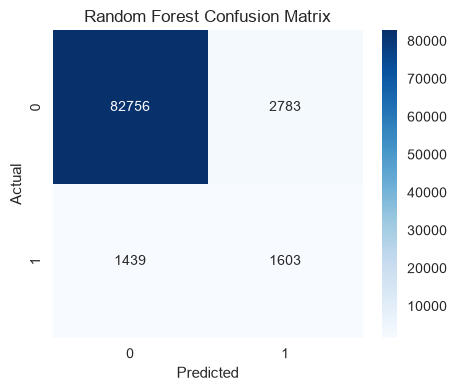

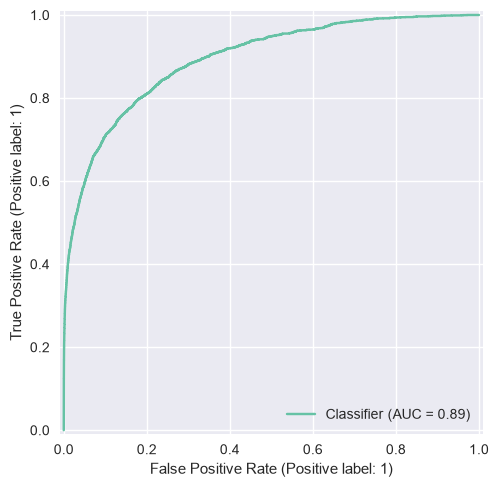

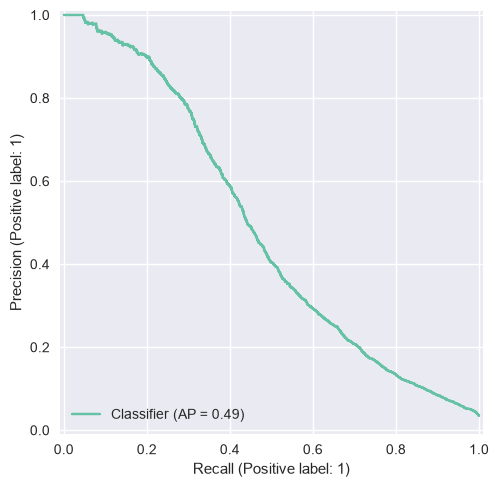

In [60]:
rf_results = evaluate_model(

    rf,

    X_train_tree,

    y_train,

    X_valid_tree,

    y_valid,

    "Random Forest"
)

---

# 8.5 Feature Importance

In [61]:
importance = pd.DataFrame({

    "Feature": X_train_tree.columns,

    "Importance": rf.feature_importances_

})

importance = importance.sort_values(

    "Importance",

    ascending=False
)

---

## Top 20 Features

In [62]:
importance.head(20)

,Feature,Importance
20,C13,0.031340
15,C1,0.019855
108,V69,0.017280
430,card1_amt_mean,0.015884
0,TransactionDT,0.015374
129,V91,0.015336
431,card1_amt_std,0.014546
109,V70,0.013911
17,C5,0.013847
427,AmountPercentile,0.013237


### Visualization

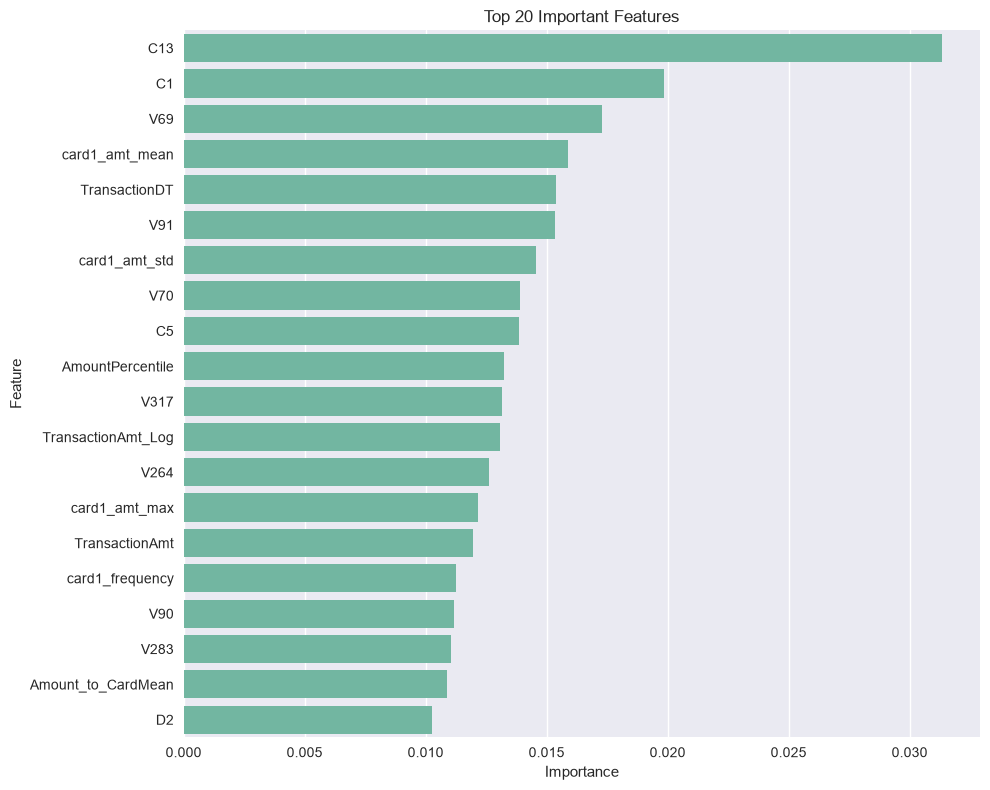

In [63]:
plt.figure(figsize=(10,8))

sns.barplot(

    data=importance.head(20),

    x="Importance",

    y="Feature",

)

plt.title("Top 20 Important Features")

plt.tight_layout()

plt.show()

Random Forest feature importance provides an initial view of influential predictors, though impurity-based importance can be biased toward variables with many unique values. We'll later complement this with SHAP values for more reliable explanations.

# 8.6 Threshold Optimization

This is something almost every beginner skips.

Our current classifier predicts
```py
predict()
```
which is equivalent to

```text
Probability > 0.5

↓

Fraud
```

That threshold is completely arbitrary.

---

## Get probabilities

In [65]:
rf_prob = rf.predict_proba(X_valid_tree)[:,1]

## Compute Precision Recall

In [66]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(

    y_valid,
    rf_prob
)

The `precision_recall_curve` function computes precision and recall across all possible decision thresholds, allowing us to select an operating point that matches business objectives.

## Compute F1

In [67]:
f1_scores = (2 * precision[:-1] * recall[:-1]
            ) / (precision[:-1] + recall[:-1] + 1e-10)

## Best Threshold

In [68]:
best_index = np.argmax(f1_scores)

best_threshold = thresholds[best_index]

print(best_threshold)

0.6031474804406755


## Plot

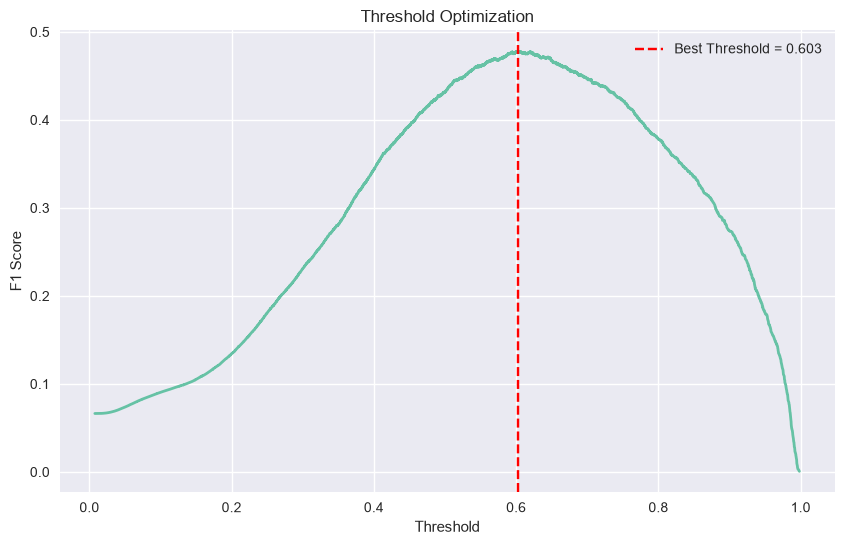

In [70]:
plt.figure(figsize=(10,6))

plt.plot(
    thresholds,
    f1_scores,
    linewidth=2
)

plt.axvline(
    best_threshold,
    color="red",
    linestyle="--",
    label=f"Best Threshold = {best_threshold:.3f}"
)

plt.xlabel("Threshold")
plt.ylabel("F1 Score")
plt.title("Threshold Optimization")
plt.legend()
plt.show()

## Predict with New Threshold

In [71]:
rf_prediction = (rf_prob >= best_threshold).astype(int)

## Evaluate Again

In [72]:
print(classification_report(y_valid, rf_prediction))

              precision    recall  f1-score   support

           0       0.98      0.99      0.98     85539
           1       0.56      0.42      0.48      3042

    accuracy                           0.97     88581
   macro avg       0.77      0.70      0.73     88581
weighted avg       0.96      0.97      0.97     88581



Rather than fixing the threshold at 0.5, tuning it on the validation set to maximize a chosen business metric (such as F1, recall, or expected cost) is recommended for imbalanced problems like fraud detection.

# 8.7 Store Results

In [73]:
rf_metrics = {
    "Model":"Random Forest",
    "ROC_AUC":roc_auc_score(
        y_valid,
        rf_prob
    ),

    "PR_AUC":average_precision_score(
        y_valid,
        rf_prob
    ),

    "F1":f1_score(
        y_valid,
        rf_prediction
    ),

    "Precision":precision_score(
        y_valid,
        rf_prediction
    ),

    "Recall":recall_score(
        y_valid,
        rf_prediction
    )
}

---

# End of Random Forest

At this point we have built a **production-quality Random Forest pipeline**, including:

* Training
* Evaluation
* Feature importance
* ROC Curve
* Precision-Recall Curve
* Threshold optimization
* Business-oriented prediction threshold

---

## Before XGBoost

Instead of manually repeating this entire workflow for **Random Forest**, **XGBoost**, **LightGBM**, and **CatBoost**, we should now refactor the notebook.

We'll create a reusable **`train_and_evaluate_model()`** function that performs:

1. Model training
2. Probability prediction
3. Threshold optimization
4. Evaluation metrics
5. Confusion matrix
6. ROC curve
7. Precision-Recall curve
8. Feature importance (when supported)
9. Runtime measurement
10. Returns a standardized metrics dictionary

This will reduce several hundred lines of duplicated code and make the remainder of the notebook significantly cleaner and easier to maintain, while still demonstrating good ML engineering practices.


# 9.1 Additional Imports

In [74]:
import time

from sklearn.metrics import (
    precision_recall_curve,
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

---

# 9.2 Threshold Optimizer

Instead of duplicating this code for every model:

```py
precision_recall_curve(...)
```
We'll build a reusable function.

In [75]:

# Find Best Classification Threshold
def find_best_threshold(y_true, probabilities):

    precision, recall, thresholds = precision_recall_curve(
        y_true,
        probabilities
    )

    f1_scores = (
        2 *
        precision[:-1] *
        recall[:-1]
    ) / (
        precision[:-1] +
        recall[:-1] +
        1e-12
    )

    best_idx = np.argmax(f1_scores)

    return {
        "threshold": thresholds[best_idx],
        "precision": precision[best_idx],
        "recall": recall[best_idx],
        "f1": f1_scores[best_idx],
        "curve_precision": precision,
        "curve_recall": recall,
        "curve_thresholds": thresholds,
        "curve_f1": f1_scores
    }

# 9.3 Universal Plot Function

In [76]:
def plot_threshold_curve(result):

    plt.figure(figsize=(10,6))

    plt.plot(
        result["curve_thresholds"],
        result["curve_f1"],
        linewidth=2
    )

    plt.axvline(
        result["threshold"],
        color="red",
        linestyle="--",
        label=f"Best = {result['threshold']:.3f}"
    )

    plt.xlabel("Threshold")

    plt.ylabel("F1 Score")

    plt.title("Threshold Optimization")

    plt.legend()

    plt.grid(alpha=0.3)

    plt.show()

# 9.4 Feature Importance Function

Not every algorithm supports feature importance.

Let's handle this automatically.

In [78]:
def plot_feature_importance(model,
                            feature_names,
                            top_n=20):

    if not hasattr(model, "feature_importances_"):

        return

    importance = pd.DataFrame({

        "Feature": feature_names,

        "Importance": model.feature_importances_

    })

    importance = importance.sort_values(
        "Importance",
        ascending=False
    )

    plt.figure(figsize=(10,8))

    sns.barplot(
        data=importance.head(top_n),
        x="Importance",
        y="Feature"
    )

    plt.title("Top Feature Importance")
    plt.tight_layout()
    plt.show()
    return importance

# 9.5 Universal Evaluation Function

This replaces almost **300 lines** of repeated code.

In [79]:
def train_and_evaluate_model(

    model,
    X_train,
    y_train,
    X_valid,
    y_valid,
    model_name,
    feature_names=None
):

    print("="*80)
    print(model_name)
    print("="*80)

    start = time.time()

    model.fit(
        X_train,
        y_train
    )

    train_time = time.time() - start

    probabilities = model.predict_proba(
        X_valid
    )[:,1]

    threshold_result = find_best_threshold(
        y_valid,
        probabilities
    )

    threshold = threshold_result["threshold"]

    predictions = (
        probabilities >= threshold
    ).astype(int)

    metrics = {
        "Model": model_name,
        "Training Time": train_time,
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_valid,
            predictions
        ),

        "Balanced Accuracy":
        balanced_accuracy_score(
            y_valid,
            predictions
        ),

        "Precision":
        precision_score(
            y_valid,
            predictions,
            zero_division=0
        ),

        "Recall":
        recall_score(
            y_valid,
            predictions
        ),

        "F1":
        f1_score(
            y_valid,
            predictions
        ),

        "ROC_AUC":
        roc_auc_score(
            y_valid,
            probabilities
        ),

        "PR_AUC":
        average_precision_score(
            y_valid,
            probabilities
        )
    }

    display(
        pd.DataFrame(metrics,index=[0])
    )

    print(classification_report(
        y_valid,
        predictions
    ))

    cm = confusion_matrix(
        y_valid,
        predictions
    )

    plt.figure(figsize=(5,4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title(f"{model_name} Confusion Matrix")
    plt.show()
    plot_threshold_curve(
        threshold_result
    )

    from sklearn.metrics import RocCurveDisplay

    RocCurveDisplay.from_predictions(
        y_valid,
        probabilities
    )

    plt.show()

    from sklearn.metrics import PrecisionRecallDisplay
    PrecisionRecallDisplay.from_predictions(
        y_valid,
        probabilities
    )
    plt.show()

    if feature_names is not None:

        plot_feature_importance(
            model,
            feature_names
        )

    return metrics

# 9.6 Model Results Storage

In [80]:
all_results = []

# 9.7 Train Random Forest

Now training a model becomes extremely simple.

Random Forest


,Model,Training Time,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Random Forest,30.387233,0.603147,0.968549,0.70361,0.555798,0.419132,0.477886,0.893543,0.485133


              precision    recall  f1-score   support

           0       0.98      0.99      0.98     85539
           1       0.56      0.42      0.48      3042

    accuracy                           0.97     88581
   macro avg       0.77      0.70      0.73     88581
weighted avg       0.96      0.97      0.97     88581



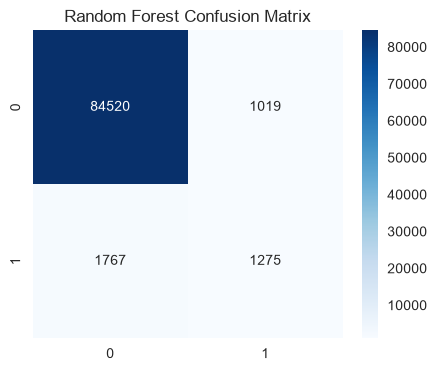

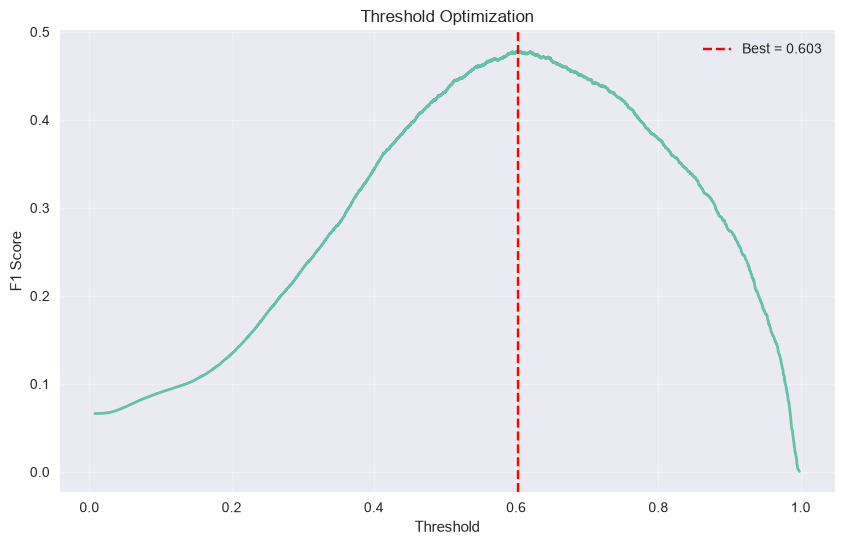

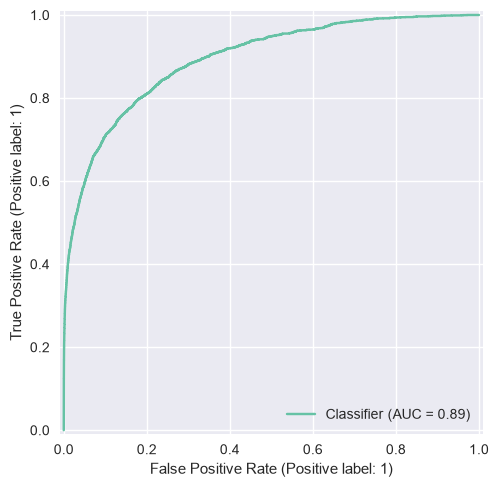

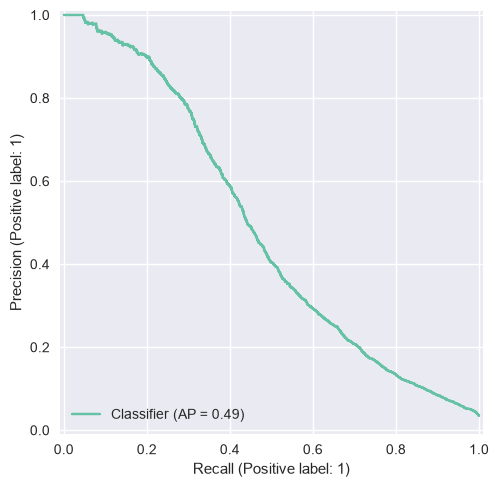

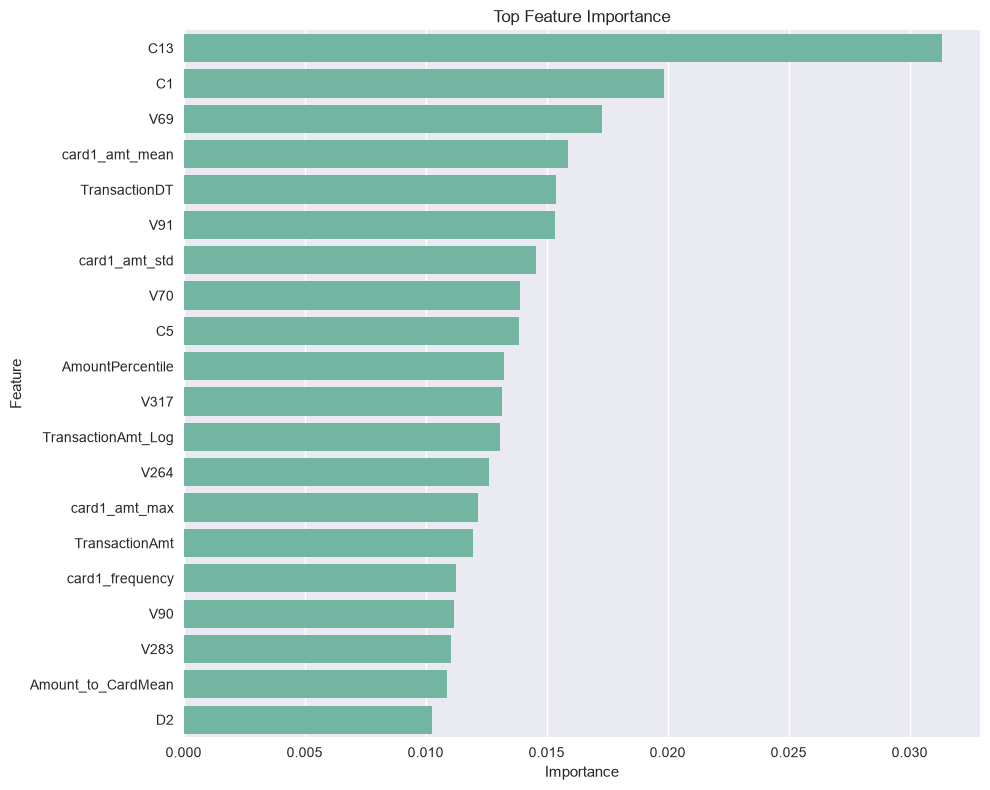

In [82]:
rf_metrics = train_and_evaluate_model(

    model=RandomForestClassifier(

        n_estimators=300,

        max_depth=20,

        min_samples_leaf=5,

        class_weight=class_weights,

        n_jobs=-1,

        random_state=RANDOM_STATE

    ),

    X_train=X_train_tree,
    y_train=y_train,
    X_valid=X_valid_tree,
    y_valid=y_valid,
    feature_names=X_train_tree.columns,
    model_name="Random Forest"

)

all_results.append(rf_metrics)

# 9.8 Train XGBoost

In [86]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="auc",
    tree_method="hist",
    n_jobs=-1
)

XGBoost


,Model,Training Time,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,XGBoost,13.725509,0.320387,0.973019,0.721935,0.655238,0.452334,0.5352,0.904847,0.545117


              precision    recall  f1-score   support

           0       0.98      0.99      0.99     85539
           1       0.66      0.45      0.54      3042

    accuracy                           0.97     88581
   macro avg       0.82      0.72      0.76     88581
weighted avg       0.97      0.97      0.97     88581



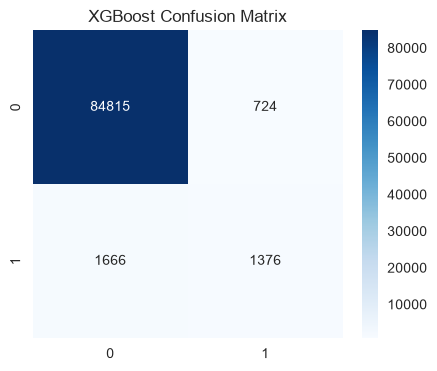

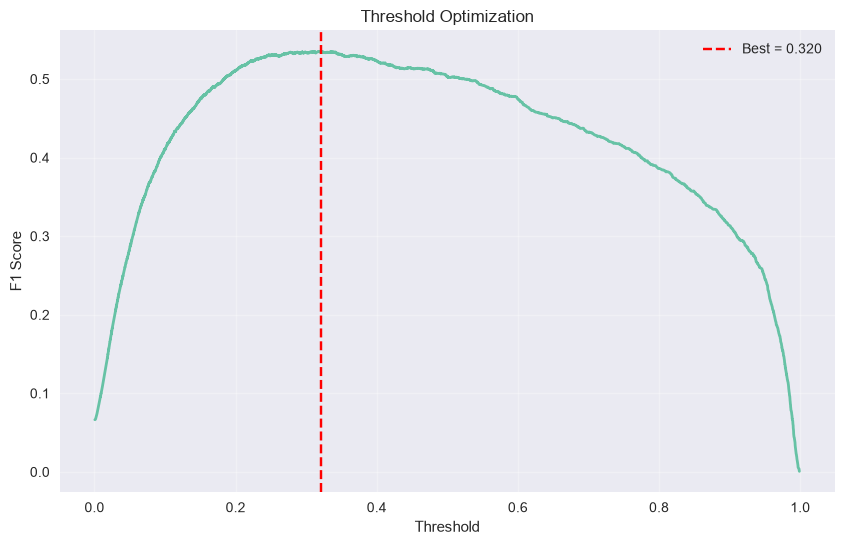

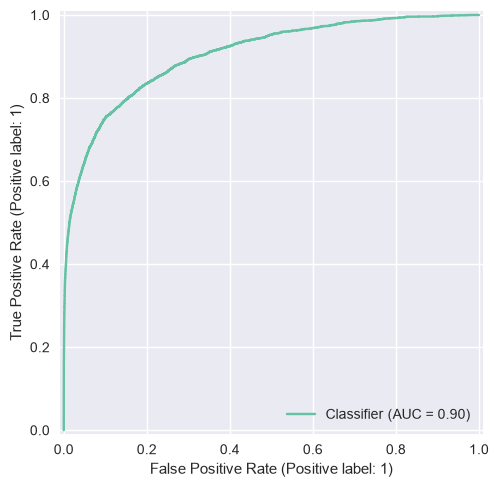

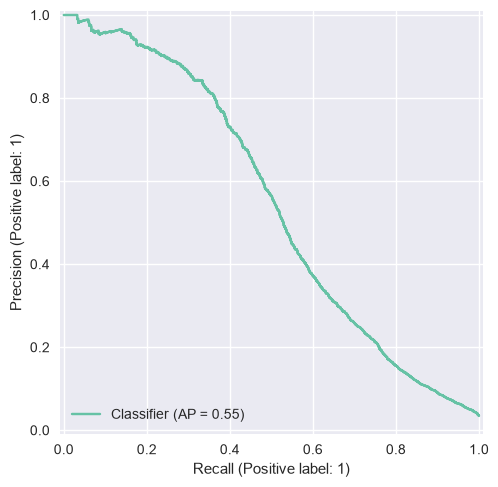

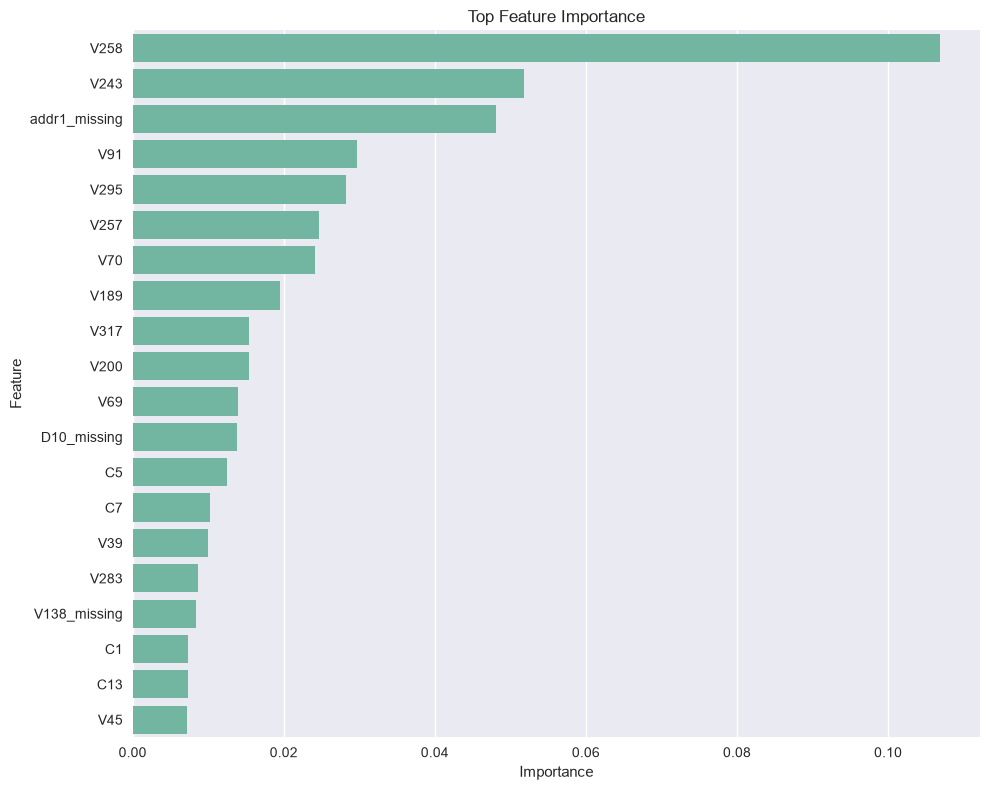

In [87]:
xgb_metrics = train_and_evaluate_model(

    model=xgb_model,
    X_train=X_train_tree,
    y_train=y_train,
    X_valid=X_valid_tree,
    y_valid=y_valid,
    feature_names=X_train_tree.columns,
    model_name="XGBoost"
)

all_results.append(xgb_metrics)

---

# 9.9 Train LightGBM

In [89]:
from lightgbm import LGBMClassifier

lgbm_model = LGBMClassifier(
    objective="binary",
    boosting_type="gbdt",
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    num_leaves=64,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=-1
)

LightGBM


,Model,Training Time,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,LightGBM,11.411901,0.216629,0.973064,0.755406,0.630262,0.521696,0.570863,0.918354,0.58956


              precision    recall  f1-score   support

           0       0.98      0.99      0.99     85539
           1       0.63      0.52      0.57      3042

    accuracy                           0.97     88581
   macro avg       0.81      0.76      0.78     88581
weighted avg       0.97      0.97      0.97     88581



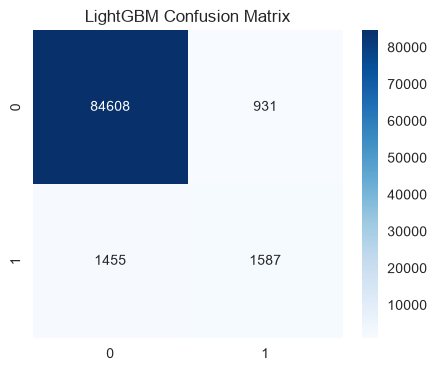

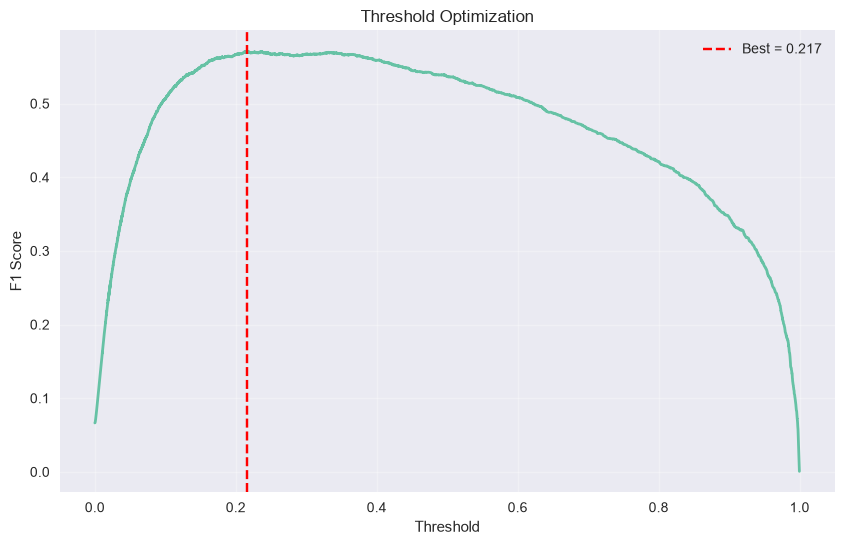

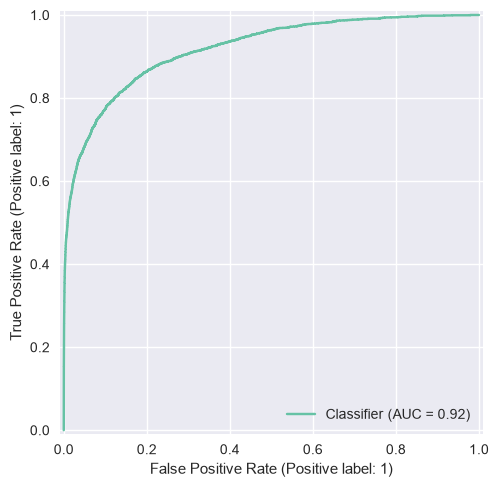

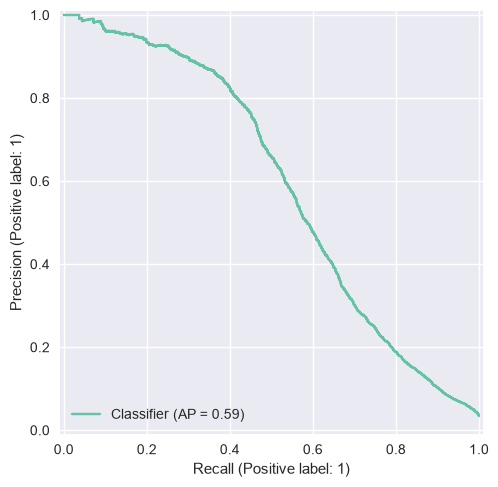

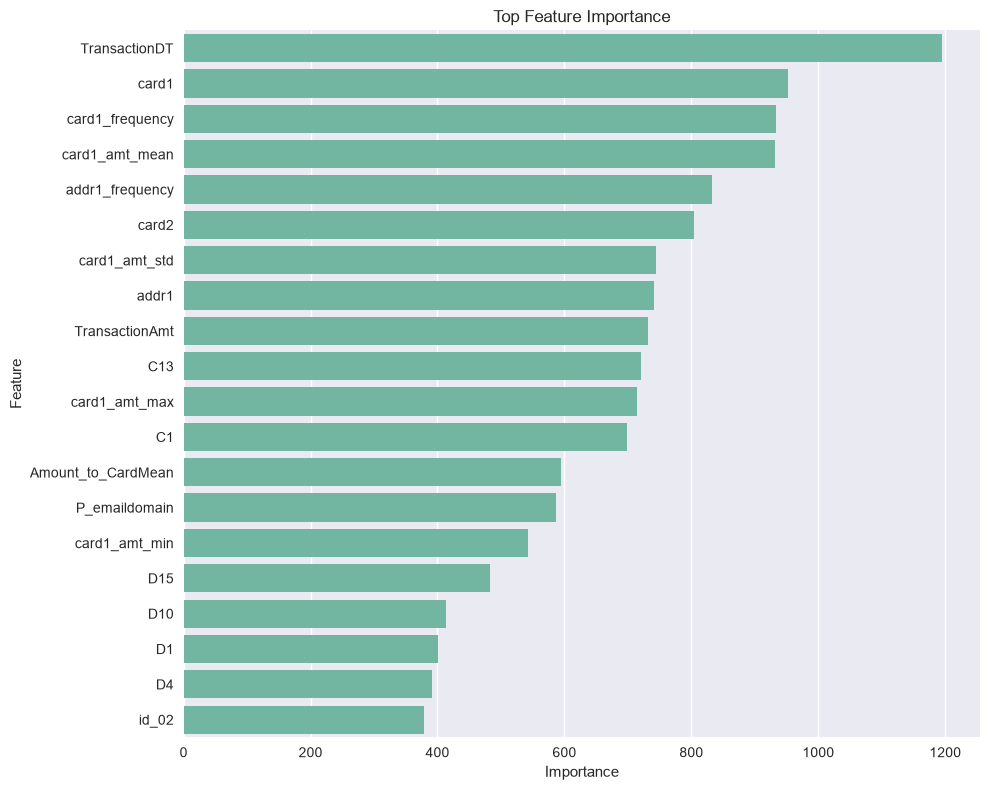

In [90]:
lgbm_metrics = train_and_evaluate_model(

    model=lgbm_model,

    X_train=X_train_tree,

    y_train=y_train,

    X_valid=X_valid_tree,

    y_valid=y_valid,

    feature_names=X_train_tree.columns,

    model_name="LightGBM"

)

all_results.append(lgbm_metrics)

---

# 9.10 Train CatBoost

In [113]:
from catboost import CatBoostClassifier

cat_model = CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=8,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=0
)

CatBoost


,Model,Training Time,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,CatBoost,41.755597,0.268861,0.97259,0.726151,0.639927,0.461538,0.536287,0.889295,0.538246


              precision    recall  f1-score   support

           0       0.98      0.99      0.99     85539
           1       0.64      0.46      0.54      3042

    accuracy                           0.97     88581
   macro avg       0.81      0.73      0.76     88581
weighted avg       0.97      0.97      0.97     88581



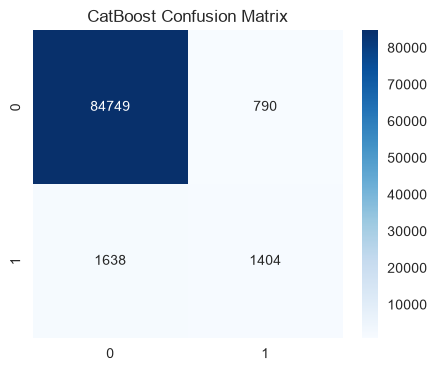

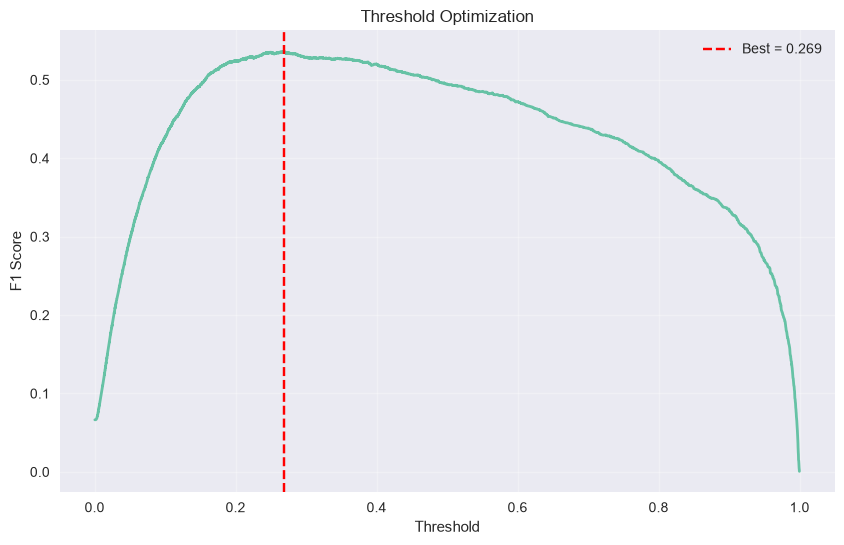

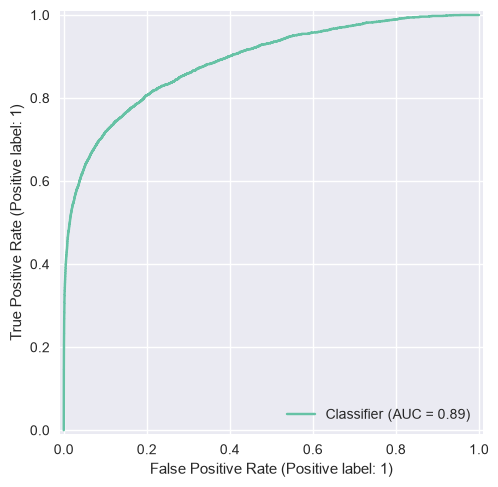

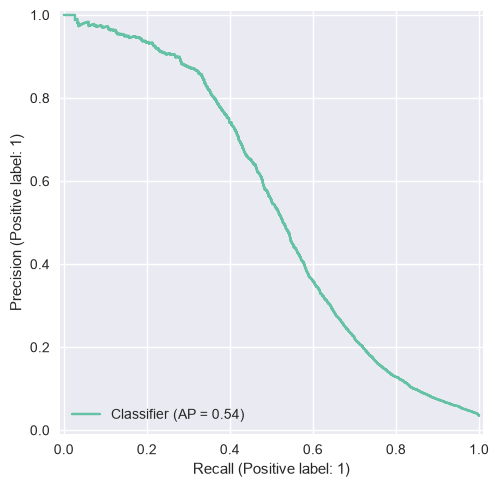

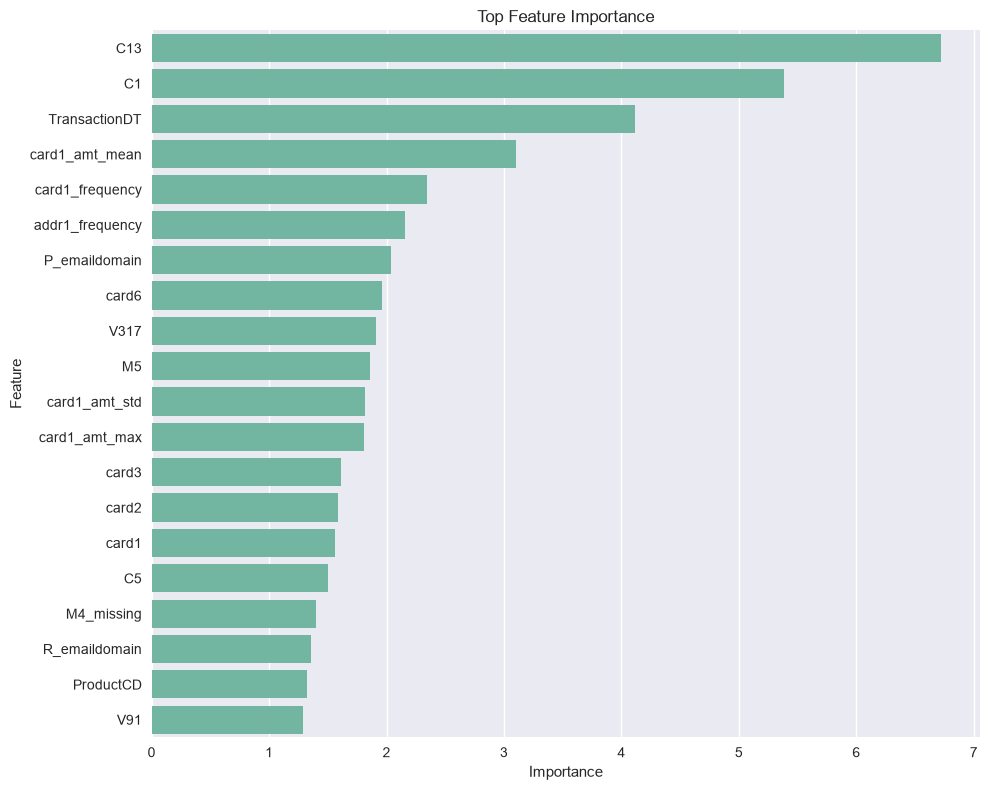

In [114]:
cat_metrics = train_and_evaluate_model(

    model=cat_model,

    X_train=X_train_tree,

    y_train=y_train,

    X_valid=X_valid_tree,

    y_valid=y_valid,

    feature_names=X_train_tree.columns,

    model_name="CatBoost"

)

all_results.append(cat_metrics)


# 9.11 Compare Models

In [109]:
results = pd.DataFrame(all_results)

results = results.sort_values(
    "PR_AUC",
    ascending=False
)

display(results)

,Model,Training Time,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
4,LightGBM,11.411901,0.216629,0.973064,0.755406,0.630262,0.521696,0.570863,0.918354,0.589560
2,XGBoost,13.154240,0.320387,0.973019,0.721935,0.655238,0.452334,0.535200,0.904847,0.545117
3,XGBoost,13.725509,0.320387,0.973019,0.721935,0.655238,0.452334,0.535200,0.904847,0.545117
5,CatBoost,42.093923,0.268861,0.972590,0.726151,0.639927,0.461538,0.536287,0.889295,0.538246
1,Random Forest,30.387233,0.603147,0.968549,0.703610,0.555798,0.419132,0.477886,0.893543,0.485133
0,Random Forest,29.090921,0.603147,0.968549,0.703610,0.555798,0.419132,0.477886,0.893543,0.485133


# 9.12 Model Comparison Plot

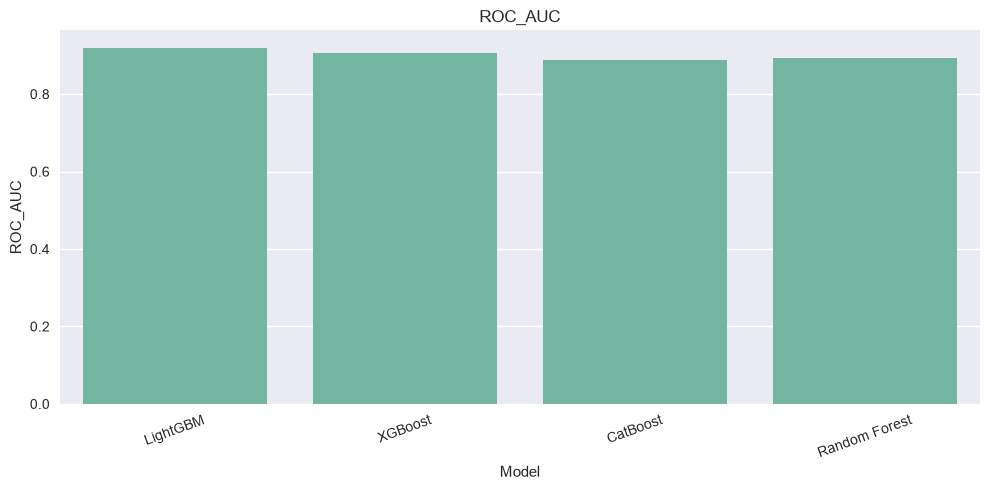

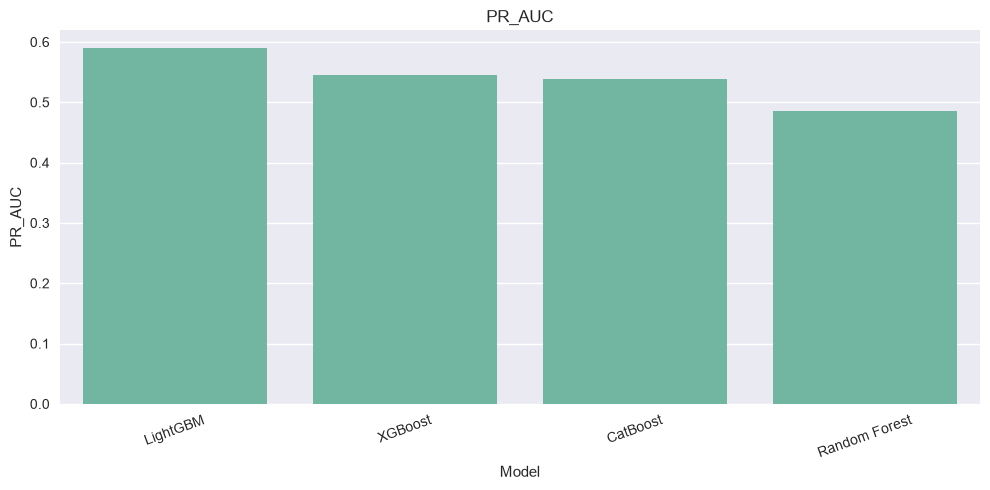

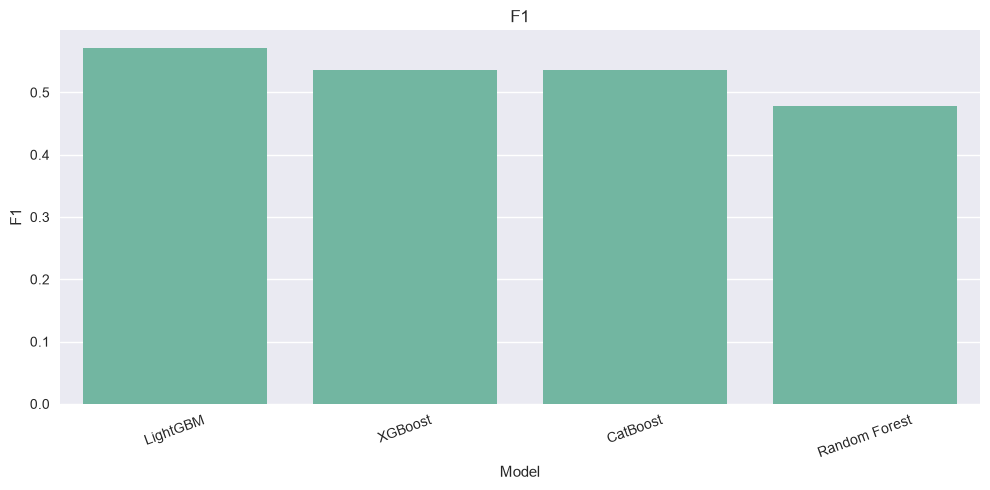

In [95]:
metrics = [

    "ROC_AUC",
    "PR_AUC",
    "F1"
]

for metric in metrics:
    plt.figure(figsize=(10,5))
    sns.barplot(
        data=results,
        x="Model",
        y=metric
    )
    plt.title(metric)
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

In [96]:

# Create Model Directory


from pathlib import Path

MODEL_DIR = Path("artifacts")
MODEL_DIR.mkdir(exist_ok=True)

print(MODEL_DIR.resolve())

C:\Users\zubim\JupyterLab\Cradit_Card_Fraud_Detection\artifacts


In [97]:
import joblib

joblib.dump(
    lgbm_model,
    MODEL_DIR / "lightgbm_model.joblib"
)

print("✓ LightGBM model saved.")

✓ LightGBM model saved.


In [103]:
metadata = {

    "model_name": "LightGBM",

    "dataset": "IEEE-CIS Fraud Detection",

    "random_state": RANDOM_STATE,

    "validation_threshold": 0.216629,

    "validation_pr_auc":
        results.loc[
            results.Model=="LightGBM",
            "PR_AUC"
        ].iloc[0],

    # "test_pr_auc":
    #     test_metrics.loc[
    #         "LightGBM Test",
    #         "PR_AUC"
    #     ],

    "features":
        list(X_train_tree.columns)

}

In [111]:
RESULT_DIR = Path('Results')
results.to_csv(RESULT_DIR/"ML_models_results.csv", index=False)


In [123]:
# Save All Trained Models

from pathlib import Path
import joblib

# Create models directory
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save Scikit-learn compatible models
models = {
    "logistic_regression.joblib": logistic,
    "decision_tree.joblib": tree,
    "random_forest.joblib": rf,
    "xgboost.joblib": xgb_model,
    "lightgbm.joblib": lgbm_model,
    # "catboost.joblib": cat_model,
}

for filename, model in models.items():
    joblib.dump(model, MODEL_DIR / filename)
    print(f"✓ Saved {filename}")

✓ Saved logistic_regression.joblib
✓ Saved decision_tree.joblib
✓ Saved random_forest.joblib
✓ Saved xgboost.joblib
✓ Saved lightgbm.joblib
